<a href="https://colab.research.google.com/github/VETTOORLIJO/DS_VettoorLijo/blob/master/NewW10Classification_ML_Assit03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [958]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve
)

from sklearn.pipeline import Pipeline


**Load the breast cancer dataset from sklearn.**

In [959]:
BC_datasets = load_breast_cancer()
print(BC_datasets.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [960]:
print(BC_datasets.filename)

breast_cancer.csv


In [961]:
print(BC_datasets.target)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 1 1 1 1 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 0
 1 0 1 0 0 1 1 1 0 0 1 0 0 0 1 1 1 0 1 1 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 1 1
 1 1 1 1 1 1 0 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 1 0 0 1 1 0 1 1 0 1 1 1 1 0 1
 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 1 1 1 1 0 1 1 0 0 0 1 0
 1 0 1 1 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 0 0 0 0 1 1 0 0 1 1
 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 0 1 0 1 1 1 1 0 1 1 1 1 1 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 0 0 0 1 1
 1 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 0
 0 1 0 0 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1
 1 0 1 1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 1 0 1 1 1 1 1 0 1 1
 0 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1
 1 1 1 1 1 1 0 1 0 1 1 0 

In [962]:
print(BC_datasets.feature_names)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [963]:
df = pd.DataFrame(BC_datasets.data,columns=BC_datasets.feature_names)
df["target"] = BC_datasets.target
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Preprocess the data to handle any missing values and perform necessary feature
scaling.

In [964]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [965]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [966]:
df.dtypes.value_counts()

,count
float64,30
int64,1


In [967]:
df['target'].value_counts()

,count
target,
1,357
0,212


In [968]:
(df==0).sum() # df.duplicated().sum()   df.isna().sum() #df.isnull().sum()

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,13
mean concave points,13
mean symmetry,0
mean fractal dimension,0


*df is not balanced + their are zeros in [mean concavity ,mean concave points ,worst concavity, worst concave points,mean concave points,mean concavity] are not big numbers so ignore it

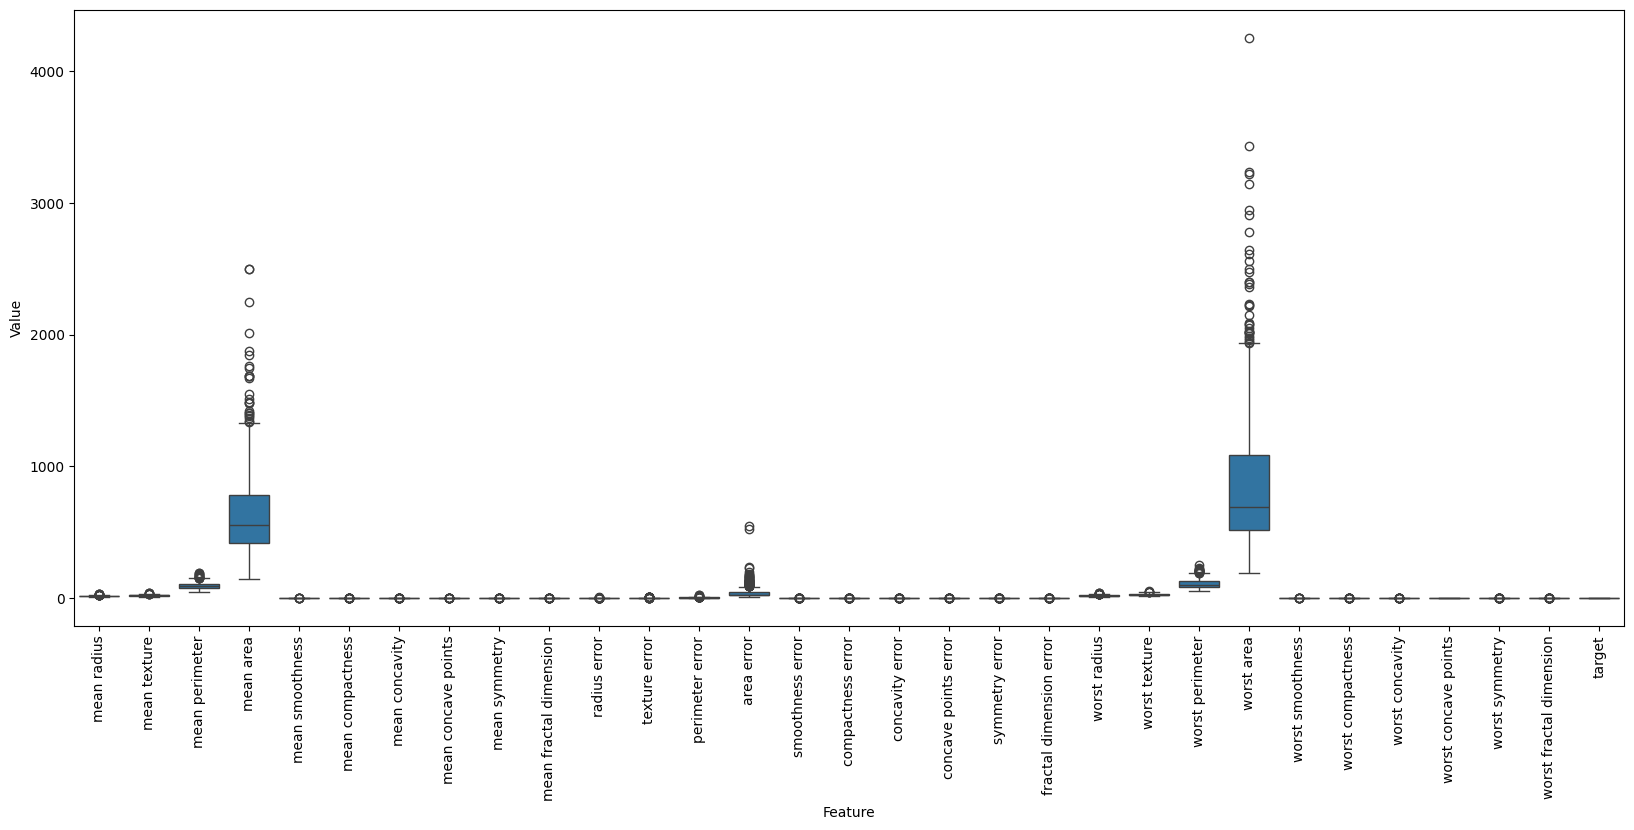

In [969]:
plt.figure(figsize=(20,8))
sns.boxplot(data=df.melt(var_name="Feature",value_name="Value"),x="Feature",y="Value")
plt.xticks(rotation=90)
plt.show()

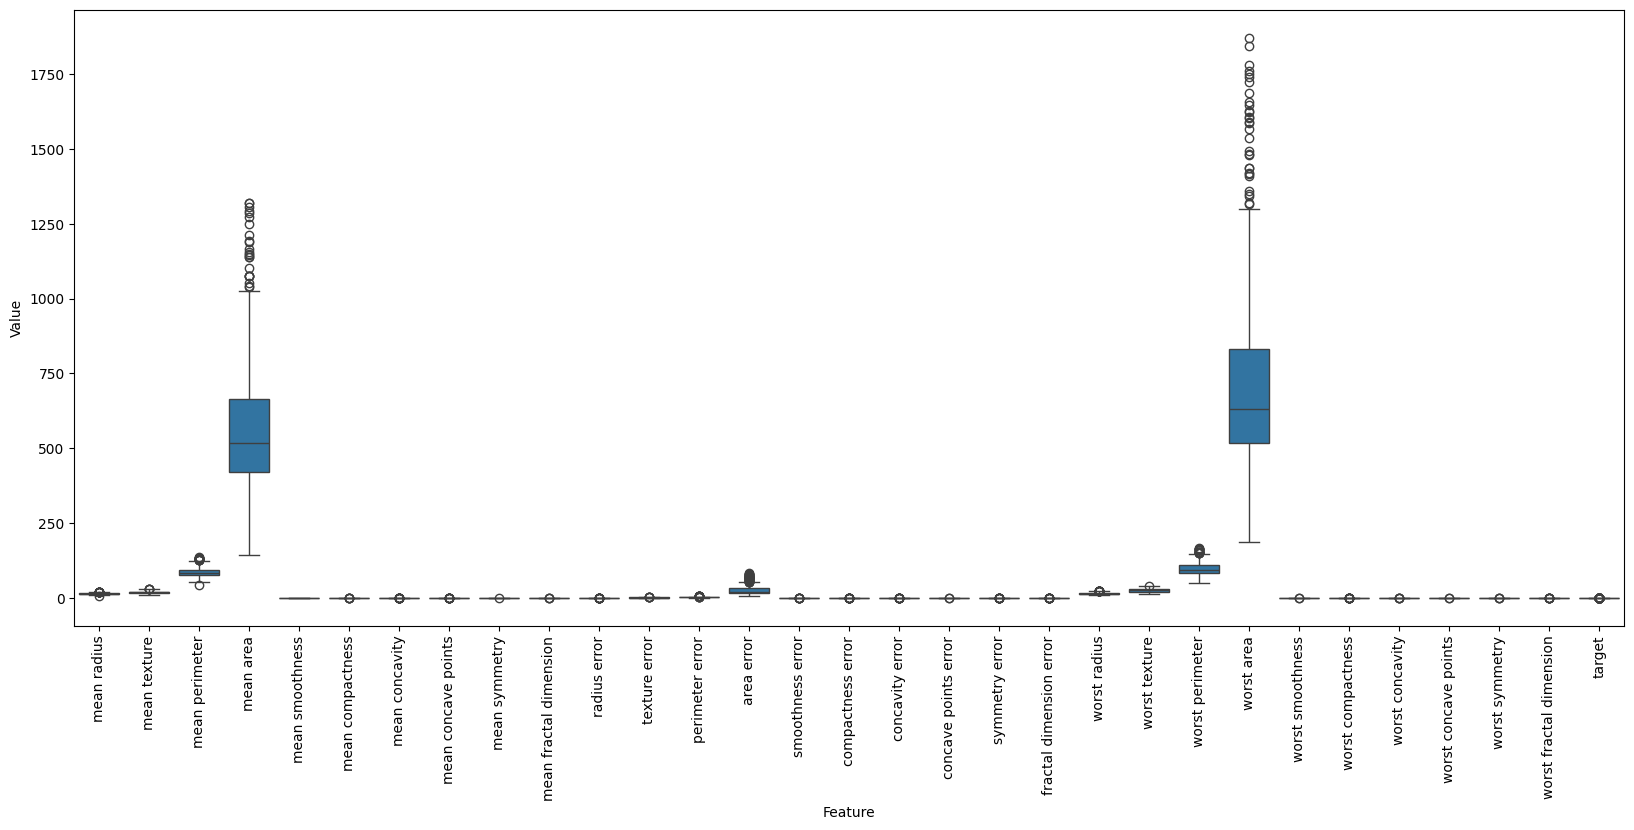

In [970]:
#IQR
q1=df.quantile(0.25)
q3=df.quantile(0.75)
IQR=q3-q1
within_boundries=(df>=q1-1.5*IQR) & (df<=q3+1.5*IQR)
clean_df=df[within_boundries.all(axis=1)]

plt.figure(figsize=(20,8))
sns.boxplot(data=clean_df.melt(var_name="Feature",value_name="Value"),x="Feature",y="Value")
plt.xticks(rotation=90)
plt.show()

In [971]:
clean_df['target'].value_counts()

,count
target,
1,300
0,98


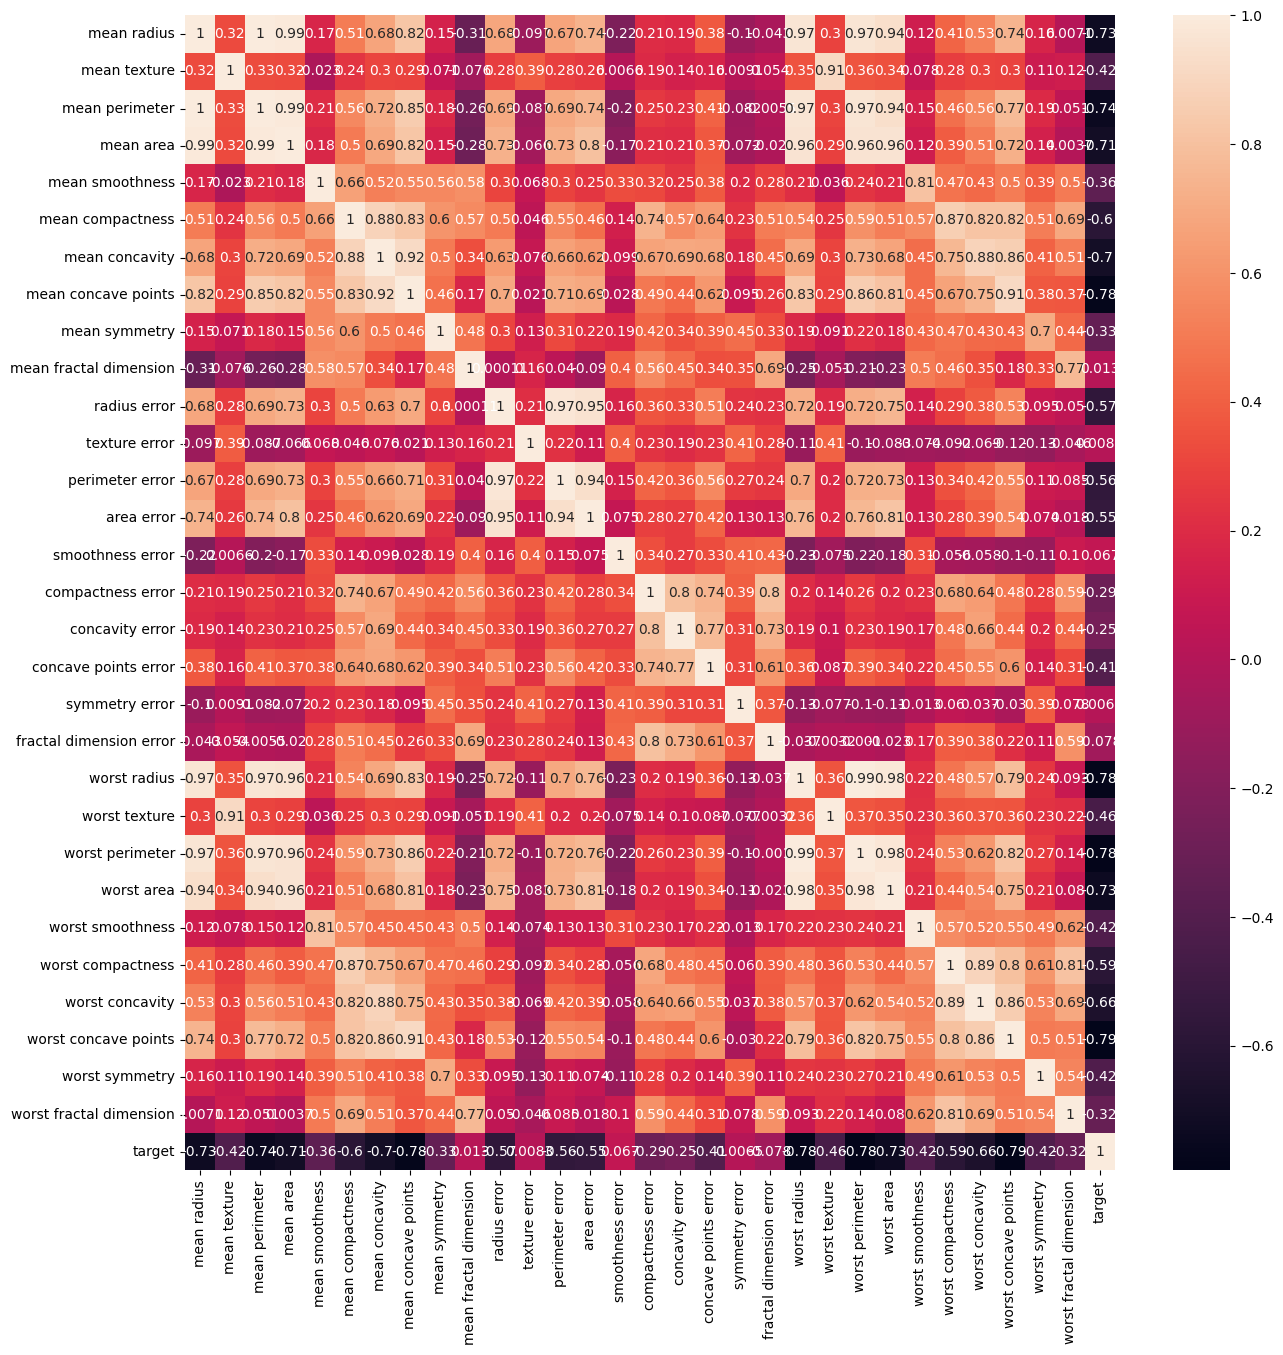

In [972]:
plt.figure(figsize=(15,15))
sns.heatmap(df.corr(),annot=True)
plt.show()

In [973]:
corr_target = df.corr(numeric_only=True)['target'].sort_values()
print(corr_target)

worst concave points      -0.793566
worst perimeter           -0.782914
mean concave points       -0.776614
worst radius              -0.776454
mean perimeter            -0.742636
worst area                -0.733825
mean radius               -0.730029
mean area                 -0.708984
mean concavity            -0.696360
worst concavity           -0.659610
mean compactness          -0.596534
worst compactness         -0.590998
radius error              -0.567134
perimeter error           -0.556141
area error                -0.548236
worst texture             -0.456903
worst smoothness          -0.421465
worst symmetry            -0.416294
mean texture              -0.415185
concave points error      -0.408042
mean smoothness           -0.358560
mean symmetry             -0.330499
worst fractal dimension   -0.323872
compactness error         -0.292999
concavity error           -0.253730
fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0

Logistic Regression model
Logistic Regression is a linear model that predicts the probability of a binary outcome.It is a good baseline model for binary classification.

In [974]:
# two data frame
#1)  df
#2) clean_df

In [975]:
result = []
classresult =[]


In [976]:
X= df.drop('target',axis=1)
y=df['target']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [977]:
def scaler_data(X_train,X_test):
    scaler = StandardScaler()
    X_train_scaler = scaler.fit_transform(X_train)
    X_test_scaler = scaler.transform(X_test)
    return X_train_scaler,X_test_scaler

In [978]:
def evaluate_model(y_test, y_pred, model_name):

    result.append({
        "model": model_name,
        "accuracy_score": round(accuracy_score(y_test, y_pred), 4),
        "precision_score": round(precision_score(y_test, y_pred), 4),
        "recall_score": round(recall_score(y_test, y_pred), 4),
        "f1_score": round(f1_score(y_test, y_pred), 4),
        "confusion_matrix": confusion_matrix(y_test, y_pred)
    })

    classresult.append({
        "model": model_name,
        "classification_report":
            classification_report(y_test, y_pred)
    })

    return (
        pd.DataFrame(result),
        pd.DataFrame(classresult)
    )


In [979]:
#Logistic Regression
X_train_scaled, X_test_scaled = scaler_data(X_train, X_test)
logic_Reg_model = LogisticRegression()
logic_Reg_model.fit(X_train_scaled,y_train)


LogisticRegression()

In [980]:
y_pred = logic_Reg_model.predict(X_test_scaled)

In [981]:
#accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [982]:
results_df, reports_df  = evaluate_model(y_test, y_pred,"logic_Reg_model with outlier ")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.979,"[[41, 2], [1, 70]]"


In [983]:
# Get predicted probabilities for the positive class
y_proba = logic_Reg_model.predict_proba(X_test_scaled)[:, 1]

# ROC-AUC and PR-AUC
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc  = average_precision_score(y_test, y_proba)

print(f" -ROC-AUC  : {roc_auc:.4f}")
print(f" -PR-AUC   : {pr_auc:.4f}")

 -ROC-AUC  : 0.9974
 -PR-AUC   : 0.9984


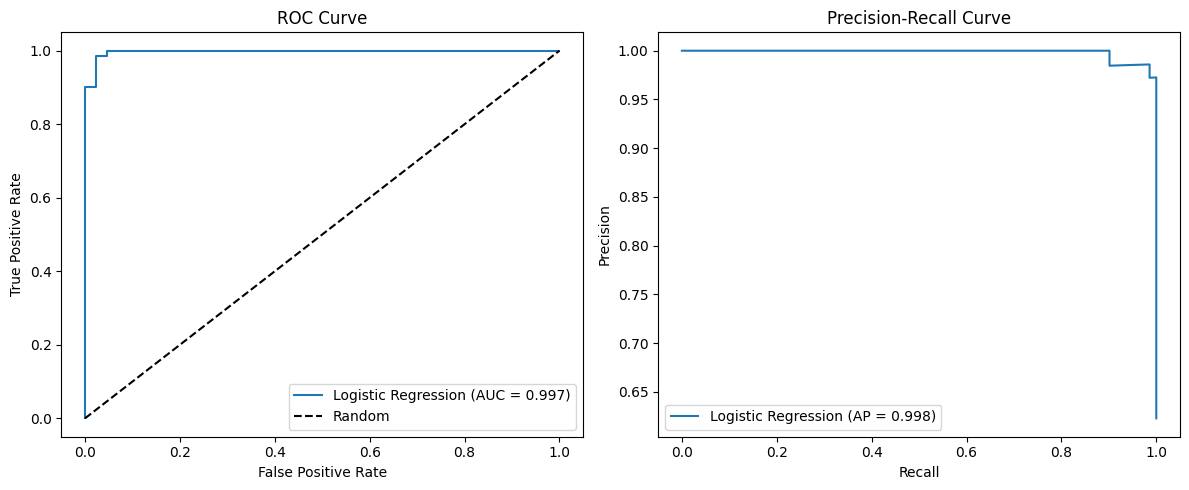

In [984]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[0].plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()

# PR curve
prec, rec, _ = precision_recall_curve(y_test, y_proba)
axes[1].plot(rec, prec, label=f"Logistic Regression (AP = {pr_auc:.3f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

without outlier LogisticRegression

In [985]:
X= clean_df.drop('target',axis=1)
y=clean_df['target']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [986]:
#Logistic Regression
X_train_scaled, X_test_scaled = scaler_data(X_train, X_test)
logic_Reg_model = LogisticRegression()
logic_Reg_model.fit(X_train_scaled,y_train)


LogisticRegression()

In [987]:
y_pred = logic_Reg_model.predict(X_test_scaled)
results_df, reports_df  = evaluate_model(y_test, y_pred,"logic_Reg_model with out outlier ")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.9790,"[[41, 2], [1, 70]]"
1,logic_Reg_model with out outlier,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"


LogisticRegression with parameters

In [988]:
X= clean_df.drop('target',axis=1)
y=clean_df['target']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [989]:
#Logistic Regression
X_train_scaled, X_test_scaled = scaler_data(X_train, X_test)
logic_Reg_model = LogisticRegression(
                                    penalty='l2',
                                    C=1.0,
                                    solver='lbfgs',
                                    max_iter=100,
                                    random_state=42
                                    )
logic_Reg_model.fit(X_train_scaled,y_train)

LogisticRegression(random_state=42)

In [990]:
y_pred = logic_Reg_model.predict(X_test_scaled)
results_df, reports_df  = evaluate_model(y_test, y_pred,"log______model with out outlier +Parameters  ")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.9790,"[[41, 2], [1, 70]]"
1,logic_Reg_model with out outlier,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
2,log______model with out outlier +Parameters,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"


Decision Tree Classifier
#1)  df
#2) clean_df
criterion = ["gini", "entropy", "log_loss"]
max_depth = [3, 5, 10, None]
min_samples_leaf = [1, 2, 5] bold text

A Decision Tree recursively splits the data based on feature values that best separate the classes
Decision Trees are highly interpretable and can capture non-linear relationships. However, they are prone to overfitting, especially with unlimited depth

In [991]:
# two data frame
#1)  df
#2) clean_df
#criterion = ["gini", "entropy", "log_loss"]
#max_depth = [3, 5, 10, None]
#min_samples_leaf = [1, 2, 5]

In [992]:
X= df.drop('target',axis=1)
y=df['target']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [993]:
D_tree_model = DecisionTreeClassifier(
                                      criterion="gini",
                                      max_depth=None,
                                      min_samples_split=2,
                                      min_samples_leaf=1,
                                     )
D_tree_model.fit(X_train,y_train)

DecisionTreeClassifier()

In [994]:
y_pred = D_tree_model.fit(X_train,y_train).predict(X_test)
results_df, reports_df  = evaluate_model(y_test, y_pred,"D_tree(gini) Classifier model with  outlier")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.9790,"[[41, 2], [1, 70]]"
1,logic_Reg_model with out outlier,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
2,log______model with out outlier +Parameters,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
3,D_tree(gini) Classifier model with outlier,0.9474,0.9577,0.9577,0.9577,"[[40, 3], [3, 68]]"


In [995]:
D_tree_model = DecisionTreeClassifier(
                                      criterion="entropy",
                                      max_depth=None,
                                      min_samples_split=2,
                                      min_samples_leaf=1,
                                     )
D_tree_model.fit(X_train,y_train)

DecisionTreeClassifier(criterion='entropy')

In [996]:
y_pred = D_tree_model.fit(X_train,y_train).predict(X_test)
results_df, reports_df  = evaluate_model(y_test, y_pred,"D_tree(entropy) Classifier model with  outlier")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.9790,"[[41, 2], [1, 70]]"
1,logic_Reg_model with out outlier,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
2,log______model with out outlier +Parameters,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
3,D_tree(gini) Classifier model with outlier,0.9474,0.9577,0.9577,0.9577,"[[40, 3], [3, 68]]"
4,D_tree(entropy) Classifier model with outlier,0.9474,0.9452,0.9718,0.9583,"[[39, 4], [2, 69]]"


In [997]:
D_tree_model = DecisionTreeClassifier(
                                      criterion="log_loss",
                                      max_depth=None,
                                      min_samples_split=2,
                                      min_samples_leaf=1,
                                     )
D_tree_model.fit(X_train,y_train)

DecisionTreeClassifier(criterion='log_loss')

In [998]:
y_pred = D_tree_model.fit(X_train,y_train).predict(X_test)
results_df, reports_df  = evaluate_model(y_test, y_pred,"D_tree(log_loss) Classifier model with  outlier")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.9790,"[[41, 2], [1, 70]]"
1,logic_Reg_model with out outlier,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
2,log______model with out outlier +Parameters,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
3,D_tree(gini) Classifier model with outlier,0.9474,0.9577,0.9577,0.9577,"[[40, 3], [3, 68]]"
4,D_tree(entropy) Classifier model with outlier,0.9474,0.9452,0.9718,0.9583,"[[39, 4], [2, 69]]"
5,D_tree(log_loss) Classifier model with outlier,0.9474,0.9333,0.9859,0.9589,"[[38, 5], [1, 70]]"


without outlier

In [999]:
X= clean_df.drop('target',axis=1)
y=clean_df['target']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [1000]:
D_tree_model =DecisionTreeClassifier(
                                      splitter="random",
                                      random_state=42
                                  )
D_tree_model.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42, splitter='random')

In [1001]:
y_pred = D_tree_model.fit(X_train,y_train).predict(X_test)
results_df, reports_df  = evaluate_model(y_test, y_pred,"D_tree Classifier model with out outlier")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.9790,"[[41, 2], [1, 70]]"
1,logic_Reg_model with out outlier,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
2,log______model with out outlier +Parameters,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
3,D_tree(gini) Classifier model with outlier,0.9474,0.9577,0.9577,0.9577,"[[40, 3], [3, 68]]"
4,D_tree(entropy) Classifier model with outlier,0.9474,0.9452,0.9718,0.9583,"[[39, 4], [2, 69]]"
5,D_tree(log_loss) Classifier model with outlier,0.9474,0.9333,0.9859,0.9589,"[[38, 5], [1, 70]]"
6,D_tree Classifier model with out outlier,0.9500,0.9322,1.0000,0.9649,"[[21, 4], [0, 55]]"


Random Forest Classifier

    * n_estimators=50, 100,500
    * criterion="gini",criterion="entropy",criterion="log_loss",
    * max_depth=5,
    * max_features="sqrt", max_features="log2",max_features=None,
    * bootstrap=True, bootstrap=False,


Random Forest is an ensemble method that builds multiple Decision Trees on bootstrapped samples of the data and random subsets of features
 It is well-suited for this dataset because it handles high-dimensional data, captures non-linear relationships, and is robust to outliers and noise.

In [1002]:
# two data frame
#1)  df
#2) clean_df
#  n_estimators=300,
# max_depth = [3, 5, 10, None]
# min_samples_leaf = [1, 2, 5]

In [1003]:
X= df.drop('target',axis=1)
y=df['target']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [1004]:
R_Forest_model = RandomForestClassifier(
                                      n_estimators=300,
                                      min_samples_split=2,
                                      min_samples_leaf=1,
                                     )
R_Forest_model.fit(X_train,y_train)

RandomForestClassifier(n_estimators=300)

In [1005]:
y_pred = R_Forest_model.fit(X_train,y_train).predict(X_test)
results_df, reports_df  = evaluate_model(y_test, y_pred,"R_Forest_Classifier model with outlier")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.9790,"[[41, 2], [1, 70]]"
1,logic_Reg_model with out outlier,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
2,log______model with out outlier +Parameters,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
3,D_tree(gini) Classifier model with outlier,0.9474,0.9577,0.9577,0.9577,"[[40, 3], [3, 68]]"
4,D_tree(entropy) Classifier model with outlier,0.9474,0.9452,0.9718,0.9583,"[[39, 4], [2, 69]]"
5,D_tree(log_loss) Classifier model with outlier,0.9474,0.9333,0.9859,0.9589,"[[38, 5], [1, 70]]"
6,D_tree Classifier model with out outlier,0.9500,0.9322,1.0000,0.9649,"[[21, 4], [0, 55]]"
7,R_Forest_Classifier model with outlier,0.9649,0.9589,0.9859,0.9722,"[[40, 3], [1, 70]]"


In [1006]:
X= clean_df.drop('target',axis=1)
y=clean_df['target']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [1007]:
R_Forest_model = RandomForestClassifier(
                                      n_estimators=300,
                                      min_samples_split=2,
                                      min_samples_leaf=1,
                                     )
R_Forest_model.fit(X_train,y_train)

RandomForestClassifier(n_estimators=300)

In [1008]:
y_pred = R_Forest_model.fit(X_train,y_train).predict(X_test)
results_df, reports_df  = evaluate_model(y_test, y_pred,"R_Forest_Classifier model with out outlier")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.9790,"[[41, 2], [1, 70]]"
1,logic_Reg_model with out outlier,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
2,log______model with out outlier +Parameters,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
3,D_tree(gini) Classifier model with outlier,0.9474,0.9577,0.9577,0.9577,"[[40, 3], [3, 68]]"
4,D_tree(entropy) Classifier model with outlier,0.9474,0.9452,0.9718,0.9583,"[[39, 4], [2, 69]]"
5,D_tree(log_loss) Classifier model with outlier,0.9474,0.9333,0.9859,0.9589,"[[38, 5], [1, 70]]"
6,D_tree Classifier model with out outlier,0.9500,0.9322,1.0000,0.9649,"[[21, 4], [0, 55]]"
7,R_Forest_Classifier model with outlier,0.9649,0.9589,0.9859,0.9722,"[[40, 3], [1, 70]]"
8,R_Forest_Classifier model with out outlier,0.9375,0.9167,1.0000,0.9565,"[[20, 5], [0, 55]]"


Support Vector Machine (SVM),

SVM finds the hyperplane that best separates the classes with the maximum margin. For non-linear data .SVMs are effective in high-dimensional spaces and are robust to overfitting, especially with the RBF kernel

* kernel="linear", "rbf","sigmoid", ["poly", degree=3]
* C = [0.1, 1, 10]
* gamma = ["scale", 0.01, 0.1, 1]



In [1009]:
# two data frame
#1)  df
#2) clean_df
# kernel="linear", "rbf","sigmoid", ["poly", degree=3]
#probability=True
# C = [0.1, 1, 10]
# gamma = ["scale", 0.01, 0.1, 1]

In [1010]:
X= df.drop('target',axis=1)
y=df['target']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [1011]:
X_train_scaled, X_test_scaled = scaler_data(X_train, X_test)
svm_models  = SVC(kernel="linear",C=1.0,gamma="scale",probability=True)
svm_models.fit(X_train_scaled,y_train)

SVC(kernel='linear', probability=True)

In [1012]:
y_pred = svm_models.predict(X_test_scaled)
results_df, reports_df  = evaluate_model(y_test, y_pred,"svm_models (linear) with outlier ")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.9790,"[[41, 2], [1, 70]]"
1,logic_Reg_model with out outlier,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
2,log______model with out outlier +Parameters,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
3,D_tree(gini) Classifier model with outlier,0.9474,0.9577,0.9577,0.9577,"[[40, 3], [3, 68]]"
4,D_tree(entropy) Classifier model with outlier,0.9474,0.9452,0.9718,0.9583,"[[39, 4], [2, 69]]"
5,D_tree(log_loss) Classifier model with outlier,0.9474,0.9333,0.9859,0.9589,"[[38, 5], [1, 70]]"
6,D_tree Classifier model with out outlier,0.9500,0.9322,1.0000,0.9649,"[[21, 4], [0, 55]]"
7,R_Forest_Classifier model with outlier,0.9649,0.9589,0.9859,0.9722,"[[40, 3], [1, 70]]"
8,R_Forest_Classifier model with out outlier,0.9375,0.9167,1.0000,0.9565,"[[20, 5], [0, 55]]"
9,svm_models (linear) with outlier,0.9561,0.9714,0.9577,0.9645,"[[41, 2], [3, 68]]"


In [1013]:
X_train_scaled, X_test_scaled = scaler_data(X_train, X_test)
svm_models  = SVC(kernel="rbf",C=1.0,gamma="scale",probability=True)
svm_models.fit(X_train_scaled,y_train)

SVC(probability=True)

In [1014]:
y_pred = svm_models.predict(X_test_scaled)
results_df, reports_df  = evaluate_model(y_test, y_pred,"svm_models (rbf) with outlier ")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.9790,"[[41, 2], [1, 70]]"
1,logic_Reg_model with out outlier,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
2,log______model with out outlier +Parameters,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
3,D_tree(gini) Classifier model with outlier,0.9474,0.9577,0.9577,0.9577,"[[40, 3], [3, 68]]"
4,D_tree(entropy) Classifier model with outlier,0.9474,0.9452,0.9718,0.9583,"[[39, 4], [2, 69]]"
5,D_tree(log_loss) Classifier model with outlier,0.9474,0.9333,0.9859,0.9589,"[[38, 5], [1, 70]]"
6,D_tree Classifier model with out outlier,0.9500,0.9322,1.0000,0.9649,"[[21, 4], [0, 55]]"
7,R_Forest_Classifier model with outlier,0.9649,0.9589,0.9859,0.9722,"[[40, 3], [1, 70]]"
8,R_Forest_Classifier model with out outlier,0.9375,0.9167,1.0000,0.9565,"[[20, 5], [0, 55]]"
9,svm_models (linear) with outlier,0.9561,0.9714,0.9577,0.9645,"[[41, 2], [3, 68]]"


In [1015]:
X= clean_df.drop('target',axis=1)
y=clean_df['target']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [1016]:
X_train_scaled, X_test_scaled = scaler_data(X_train, X_test)
svm_models  = SVC(kernel="sigmoid",C=1.0,gamma="scale",probability=True)
svm_models.fit(X_train_scaled,y_train)

SVC(kernel='sigmoid', probability=True)

In [1017]:
y_pred = svm_models.predict(X_test_scaled)
results_df, reports_df  = evaluate_model(y_test, y_pred,"svm_models (linear) with out outlier ")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.9790,"[[41, 2], [1, 70]]"
1,logic_Reg_model with out outlier,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
2,log______model with out outlier +Parameters,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
3,D_tree(gini) Classifier model with outlier,0.9474,0.9577,0.9577,0.9577,"[[40, 3], [3, 68]]"
4,D_tree(entropy) Classifier model with outlier,0.9474,0.9452,0.9718,0.9583,"[[39, 4], [2, 69]]"
5,D_tree(log_loss) Classifier model with outlier,0.9474,0.9333,0.9859,0.9589,"[[38, 5], [1, 70]]"
6,D_tree Classifier model with out outlier,0.9500,0.9322,1.0000,0.9649,"[[21, 4], [0, 55]]"
7,R_Forest_Classifier model with outlier,0.9649,0.9589,0.9859,0.9722,"[[40, 3], [1, 70]]"
8,R_Forest_Classifier model with out outlier,0.9375,0.9167,1.0000,0.9565,"[[20, 5], [0, 55]]"
9,svm_models (linear) with outlier,0.9561,0.9714,0.9577,0.9645,"[[41, 2], [3, 68]]"


K-Nearest Neighbors (KNN)

KNN is a non-parametric, instance-based learning algorithm. It classifies a new sample based on the majority class of its k nearest neighbors in the feature space. it is a distance metric . KNN is simple and can capture complex decision boundaries. However, it is sensitive to the scale of features and the choice of k. It is  expensive for large datasets

* 'n_neighbors': [3, 5, 7, 9],
*  weights': ['uniform', 'distance'],
*  metric': ['euclidean', 'manhattan'],
*    ['algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']]
*  cv=5,
* scoring='f1',
* n_jobs=-1


In [1018]:
# two data frame
#1)  df
# #2) clean_df
#     'n_neighbors': [3, 5, 7, 9],
#     'weights': ['uniform', 'distance'],
#     'metric': ['euclidean', 'manhattan'],
#     'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
#     *cv=5,
#     scoring='f1',
#     n_jobs=-1


In [1019]:
X= df.drop('target',axis=1)
y=df['target']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [1020]:
X_train_scaled, X_test_scaled = scaler_data(X_train, X_test)

In [1021]:
#  hyperparameter tuning
param_grid = {
    'n_neighbors':[3,5,7,9,11],
    'weights':['uniform','distance'],
    'metric':['euclidean','manhattan']
}

In [1022]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(
                    KNeighborsClassifier(),
                    param_grid=param_grid,
                    cv=5,                              #Split training data into 5 parts ,Train on 4 parts, test on 1 part
                    scoring='f1',                       #Pick the parameter combination with the highest F1 score
                    n_jobs=-1                           #  n_jobs=-1  Use all CPU cores,  n_jobs=4  Uses four cores.
                  )
grid.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'metric': ['euclidean', 'manhattan'],
                         'n_neighbors': [3, 5, 7, 9, 11],
                         'weights': ['uniform', 'distance']},
             scoring='f1')

In [1023]:
print(grid.best_params_)
print(grid.best_score_)

{'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'uniform'}
0.9729301754268995


In [1024]:
best_knn = grid.best_estimator_
y_pred = best_knn.predict(X_test_scaled)
results_df, reports_df  = evaluate_model(y_test,y_pred,"Best KNN with outlier")
display(results_df)

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,logic_Reg_model with outlier,0.9737,0.9722,0.9859,0.9790,"[[41, 2], [1, 70]]"
1,logic_Reg_model with out outlier,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
2,log______model with out outlier +Parameters,0.9500,0.9474,0.9818,0.9643,"[[22, 3], [1, 54]]"
3,D_tree(gini) Classifier model with outlier,0.9474,0.9577,0.9577,0.9577,"[[40, 3], [3, 68]]"
4,D_tree(entropy) Classifier model with outlier,0.9474,0.9452,0.9718,0.9583,"[[39, 4], [2, 69]]"
5,D_tree(log_loss) Classifier model with outlier,0.9474,0.9333,0.9859,0.9589,"[[38, 5], [1, 70]]"
6,D_tree Classifier model with out outlier,0.9500,0.9322,1.0000,0.9649,"[[21, 4], [0, 55]]"
7,R_Forest_Classifier model with outlier,0.9649,0.9589,0.9859,0.9722,"[[40, 3], [1, 70]]"
8,R_Forest_Classifier model with out outlier,0.9375,0.9167,1.0000,0.9565,"[[20, 5], [0, 55]]"
9,svm_models (linear) with outlier,0.9561,0.9714,0.9577,0.9645,"[[41, 2], [3, 68]]"


summary:
 SVM (RBF kernel) — highest accuracy (98.25%), perfect recall (1.0), best F1-score (0.9861). Only 2 false positives, no false negatives.

Logistic Regression with outliers — 97.37% accuracy, 0.979 F1-score. A simple linear model works very well here.

Random Forest with outliers — strong but slightly lower (96.49% accuracy, 0.9722 F1-score).

Decision Trees:Worst performers among single models, likely due to overfitting

Removing outliers (IQR) generally hurt performance — e.g., Logistic Regression dropped from 0.9737 to 0.9500, Random Forest from 0.9649 to 0.9375. The "outliers" likely carried useful information, or too many samples were removed.

KNN: used  GridSearchCV to do Hyperparameter .

In [1025]:
reports_df

,model,classification_report
0,logic_Reg_model with outlier,precision recall f1-score ...
1,logic_Reg_model with out outlier,precision recall f1-score ...
2,log______model with out outlier +Parameters,precision recall f1-score ...
3,D_tree(gini) Classifier model with outlier,precision recall f1-score ...
4,D_tree(entropy) Classifier model with outlier,precision recall f1-score ...
5,D_tree(log_loss) Classifier model with outlier,precision recall f1-score ...
6,D_tree Classifier model with out outlier,precision recall f1-score ...
7,R_Forest_Classifier model with outlier,precision recall f1-score ...
8,R_Forest_Classifier model with out outlier,precision recall f1-score ...
9,svm_models (linear) with outlier,precision recall f1-score ...


Best Performing: SVM (RBF kernel, with outliers) — accuracy 0.9825, recall 1.0, F1-score 0.9861. Excellent at identifying benign cases with balanced precision and recall.

Worst Performing: SVM (Sigmoid kernel, without outliers) — lowest accuracy (0.9375) and F1-score (0.9550). The sigmoid kernel is a poor fit here, and removing outliers hurt performance.